# 💻 Laptop Price Predictor — End-to-End Regression Project

**Business problem:** An online electronics store lists 1,300+ laptops. Pricing a new model by hand is slow, and buyers can't tell if a laptop is fairly priced.
**Goal:** Predict a laptop's price (₹) from its specs. Also group laptops into market segments (Budget → Premium) *without* using the price.

| Step | What we do | Concept from the course |
|---|---|---|
| 1 | Define the problem | [Part 1 – Steps of an ML project](https://youtu.be/1L420xXpDTg?t=1520) |
| 2 | Explore the data | [Part 1 – EDA](https://youtu.be/1L420xXpDTg?t=1695) |
| 3–4 | Clean messy text columns, engineer new features | [Part 1 – Data cleaning](https://youtu.be/1L420xXpDTg?t=2025), [Feature engineering](https://youtu.be/1L420xXpDTg?t=3250) |
| 5 | Pick useful features | [Part 1 – Feature selection](https://youtu.be/1L420xXpDTg?t=3478) |
| 6 | Encode + scale, train/test split | [Part 1 – Preprocessing](https://youtu.be/1L420xXpDTg?t=2550) |
| 7 | Linear Regression **from scratch** with Gradient Descent | [Part 2 – Cost function](https://youtu.be/Lb0JzFtTmBs?t=2327), [Gradient descent](https://youtu.be/Lb0JzFtTmBs?t=2790) |
| 8 | MSE, RMSE, MAE, R² | [Part 2 – Evaluation](https://youtu.be/Lb0JzFtTmBs?t=5326) |
| 9 | Overfitting vs underfitting | [Part 2 – Overfitting & underfitting](https://youtu.be/Lb0JzFtTmBs?t=6377) |
| 10 | Compare models with cross-validation | [Part 4 – Cross validation](https://youtu.be/UFAHXZW2hU8?t=646) |
| 11 | GridSearchCV + RandomizedSearchCV | [Part 4 – Grid search](https://youtu.be/UFAHXZW2hU8?t=2006), [Random search](https://youtu.be/UFAHXZW2hU8?t=3912) |
| 12 | Bagging, Boosting, Stacking | [Part 4 – Ensemble learning](https://youtu.be/UFAHXZW2hU8?t=4449) |
| 13 | Final test + feature importance | — |
| 14 | K-Means segments, DBSCAN outliers, PCA | [Part 4 – K-Means](https://youtu.be/UFAHXZW2hU8?t=9931), [DBSCAN](https://youtu.be/UFAHXZW2hU8?t=11909), [PCA](https://youtu.be/UFAHXZW2hU8?t=12593) |

## 1. Problem definition
- **Type of ML:** Supervised learning (we have the correct price for every laptop), **regression** (the output is a number, not a category).
- **Input (X):** specs such as brand, RAM, CPU, screen and storage. **Output (y):** price in ₹.
- **How we judge success:** R² (how much of the price variation we explain) and MAE in ₹ (how far off we are on average).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

raw = pd.read_csv("data/laptop_data.csv")
print(raw.shape)
raw.head()

(1303, 12)


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


## 2. Exploratory Data Analysis (EDA)
First, get to know the data: its size, column types, missing values and duplicates.

In [2]:
print("Missing values:", raw.isna().sum().sum())
print("Duplicate rows (ignoring the index column):", raw.drop(columns="Unnamed: 0").duplicated().sum())
raw.dtypes

Missing values: 0
Duplicate rows (ignoring the index column): 29


Unnamed: 0            int64
Company                 str
TypeName                str
Inches              float64
ScreenResolution        str
Cpu                     str
Ram                     str
Memory                  str
Gpu                     str
OpSys                   str
Weight                  str
Price               float64
dtype: object

**What we notice:**
- `Ram` (`"8GB"`) and `Weight` (`"1.37kg"`) are numbers stored as **text**, so the model can't use them yet.
- `ScreenResolution`, `Cpu`, `Memory` and `Gpu` are long messy strings with many unique values. Useful information is hidden inside them.

In [3]:
for col in ["ScreenResolution", "Cpu", "Memory", "Gpu"]:
    print(f"{col:17s}: {raw[col].nunique():3d} unique values, e.g. {raw[col].unique()[:3].tolist()}")

ScreenResolution :  40 unique values, e.g. ['IPS Panel Retina Display 2560x1600', '1440x900', 'Full HD 1920x1080']
Cpu              : 118 unique values, e.g. ['Intel Core i5 2.3GHz', 'Intel Core i5 1.8GHz', 'Intel Core i5 7200U 2.5GHz']
Memory           :  39 unique values, e.g. ['128GB SSD', '128GB Flash Storage', '256GB SSD']
Gpu              : 110 unique values, e.g. ['Intel Iris Plus Graphics 640', 'Intel HD Graphics 6000', 'Intel HD Graphics 620']


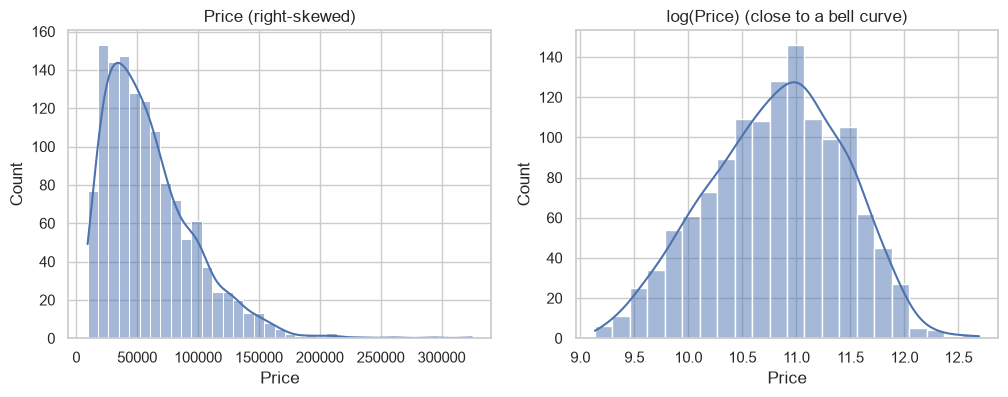

Skewness before: 1.52 | after log: -0.17


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(raw["Price"], kde=True, ax=ax[0]).set_title("Price (right-skewed)")
sns.histplot(np.log(raw["Price"]), kde=True, ax=ax[1]).set_title("log(Price) (close to a bell curve)")
plt.show()
print(f"Skewness before: {raw.Price.skew():.2f} | after log: {np.log(raw.Price).skew():.2f}")

**Insight:** Most laptops are cheap, and a few very expensive ones create a long right tail. Linear models work better on a symmetric target, so **we predict `log(Price)`** and convert back with `exp()` at the end. A side benefit: errors become *percentage-like*. Being ₹5,000 off on a ₹20,000 laptop is a bigger mistake than on a ₹2,00,000 one.

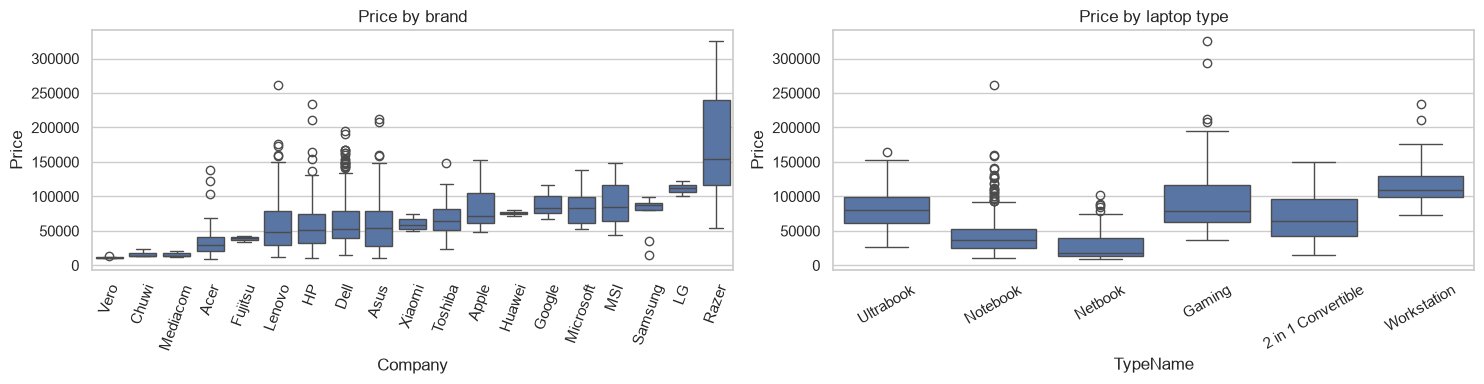

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
order = raw.groupby("Company")["Price"].median().sort_values().index
sns.boxplot(data=raw, x="Company", y="Price", order=order, ax=ax[0])
ax[0].tick_params(axis="x", rotation=70)
ax[0].set_title("Price by brand")
sns.boxplot(data=raw, x="TypeName", y="Price", ax=ax[1])
ax[1].tick_params(axis="x", rotation=30)
ax[1].set_title("Price by laptop type")
plt.tight_layout()
plt.show()

**Insight:** Brand and type matter a lot. Workstations and gaming laptops cost the most, netbooks the least. Razer/Apple/MSI sit at the top, Vero/Mediacom at the bottom.

## 3–4. Data cleaning + feature engineering
The logic lives in [`features.py`](features.py) so the **Streamlit app reuses exactly the same code** (no train/serve mismatch).

| New feature | Built from | Why it helps |
|---|---|---|
| `Ram`, `Weight` | `"8GB"`, `"1.37kg"` | text → numbers |
| `Touchscreen`, `IPS` | `ScreenResolution` | premium screen flags (0/1) |
| `PPI` (pixels per inch) | resolution + inches | **one** sharpness number instead of 3 columns: √(x² + y²) / inches |
| `Cpu_brand` | `Cpu` (118 values) | grouped into i7 / i5 / i3 / Other Intel / AMD |
| `Cpu_GHz` | `Cpu` | clock speed |
| `SSD`, `HDD` (GB) | `Memory` | `"128GB SSD + 1TB HDD"` → SSD=128, HDD=1000 |
| `Gpu_brand` | `Gpu` | Intel / Nvidia / AMD |
| `OS` | `OpSys` | Windows / Mac / Other |

In [6]:
from features import (CATEGORICAL_FEATURES, FEATURES, NUMERIC_FEATURES, TARGET,
                      _storage_gb, clean_and_engineer, cpu_brand, ppi)

print('PPI of a 15.6" Full HD screen :', round(ppi(1920, 1080, 15.6), 1))
print('PPI of a 13.3" Retina screen  :', round(ppi(2560, 1600, 13.3), 1))
print("CPU grouping:", cpu_brand("Intel Core i5 7200U 2.5GHz"), "|",
      cpu_brand("Intel Celeron Dual Core N3350 1.1GHz"), "|", cpu_brand("AMD A9-Series 9420 3GHz"))
mem = "128GB SSD +  1TB HDD"
print(f"'{mem}' -> SSD = {_storage_gb(mem, 'SSD'):.0f} GB, HDD = {_storage_gb(mem, 'HDD'):.0f} GB")

PPI of a 15.6" Full HD screen : 141.2
PPI of a 13.3" Retina screen  : 227.0
CPU grouping: Intel Core i5 | Other Intel | AMD
'128GB SSD +  1TB HDD' -> SSD = 128 GB, HDD = 1000 GB


In [7]:
df = clean_and_engineer(raw)
print(f"Rows: raw {len(raw)} -> clean {len(df)} "
      f"({len(raw) - len(df)} removed: duplicates + 2 one-off ARM/Samsung rows)")
df.head()

Rows: raw 1303 -> clean 1273 (30 removed: duplicates + 2 one-off ARM/Samsung rows)


,Ram,Weight,PPI,Cpu_GHz,SSD,HDD,Touchscreen,IPS,Company,TypeName,Cpu_brand,Gpu_brand,OS,Price
0,8,1.37,226.98,2.3,128.0,0.0,0,1,Apple,Ultrabook,Intel Core i5,Intel,Mac,71378.6832
1,8,1.34,127.68,1.8,128.0,0.0,0,0,Apple,Ultrabook,Intel Core i5,Intel,Mac,47895.5232
2,8,1.86,141.21,2.5,256.0,0.0,0,0,HP,Notebook,Intel Core i5,Intel,Other/Linux/No OS,30636.0000
3,16,1.83,220.53,2.7,512.0,0.0,0,1,Apple,Ultrabook,Intel Core i7,AMD,Mac,135195.3360
4,8,1.37,226.98,3.1,256.0,0.0,0,1,Apple,Ultrabook,Intel Core i5,Intel,Mac,96095.8080


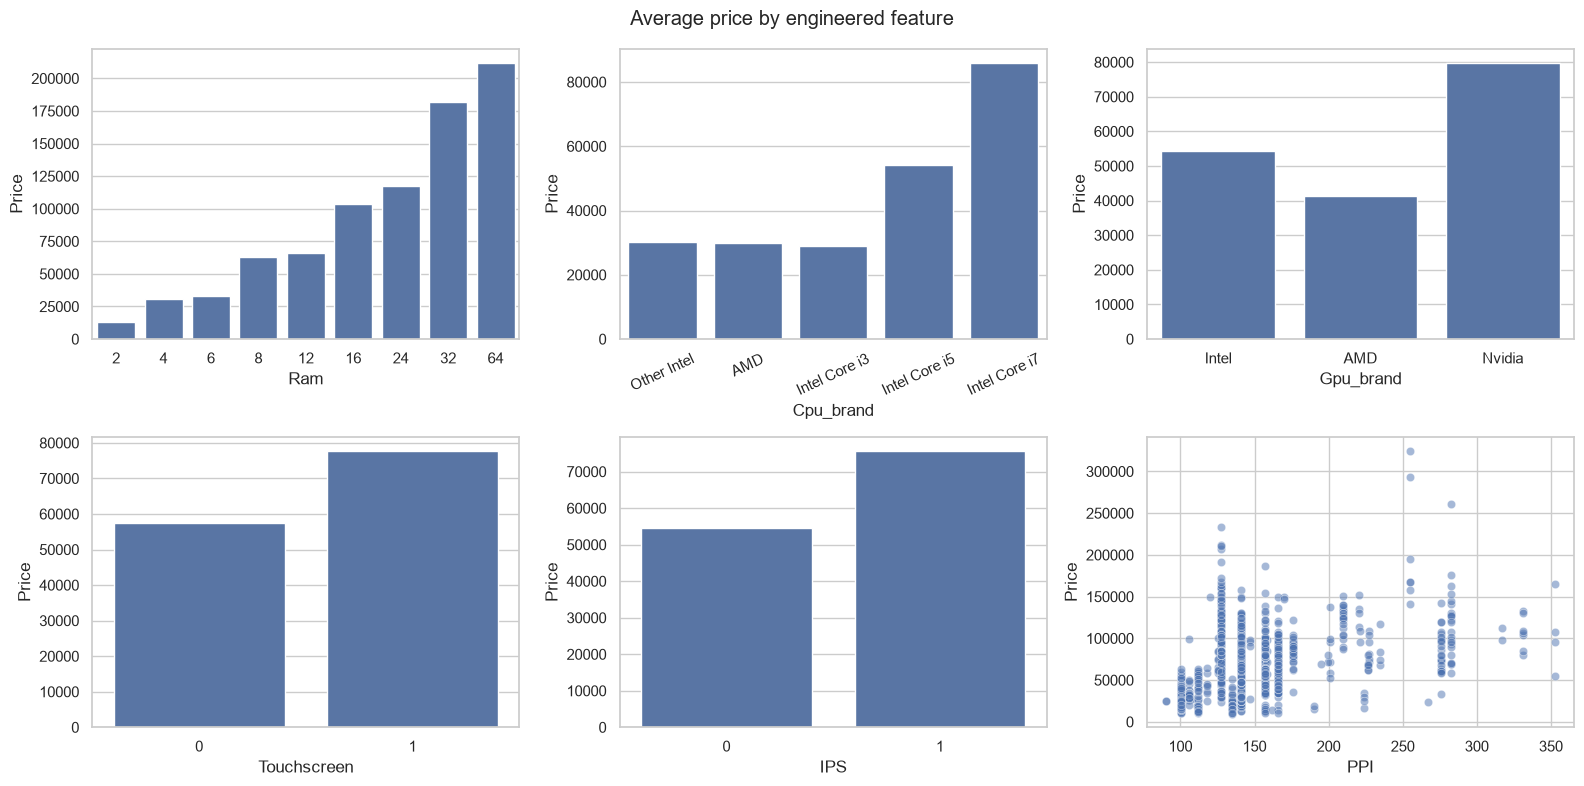

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.barplot(data=df, x="Ram", y="Price", ax=ax[0, 0], errorbar=None)
sns.barplot(data=df, x="Cpu_brand", y="Price", ax=ax[0, 1], errorbar=None,
            order=["Other Intel", "AMD", "Intel Core i3", "Intel Core i5", "Intel Core i7"])
ax[0, 1].tick_params(axis="x", rotation=25)
sns.barplot(data=df, x="Gpu_brand", y="Price", ax=ax[0, 2], errorbar=None)
sns.barplot(data=df, x="Touchscreen", y="Price", ax=ax[1, 0], errorbar=None)
sns.barplot(data=df, x="IPS", y="Price", ax=ax[1, 1], errorbar=None)
sns.scatterplot(data=df, x="PPI", y="Price", ax=ax[1, 2], alpha=0.5)
plt.suptitle("Average price by engineered feature")
plt.tight_layout()
plt.show()

**Insights:** Price climbs steeply with RAM. i7 > i5 > i3 > AMD/others. Nvidia GPUs (gaming) are the most expensive. Touchscreen and IPS both add a premium. Sharper screens (higher PPI) tend to cost more.

## 5. Feature selection
We keep features that relate to price and drop ones that repeat each other:
- `Inches`, `X_res` and `Y_res` are folded into **PPI**. Keeping all of them would add *multicollinearity* (columns telling the same story).
- The raw text columns are replaced by their engineered versions.

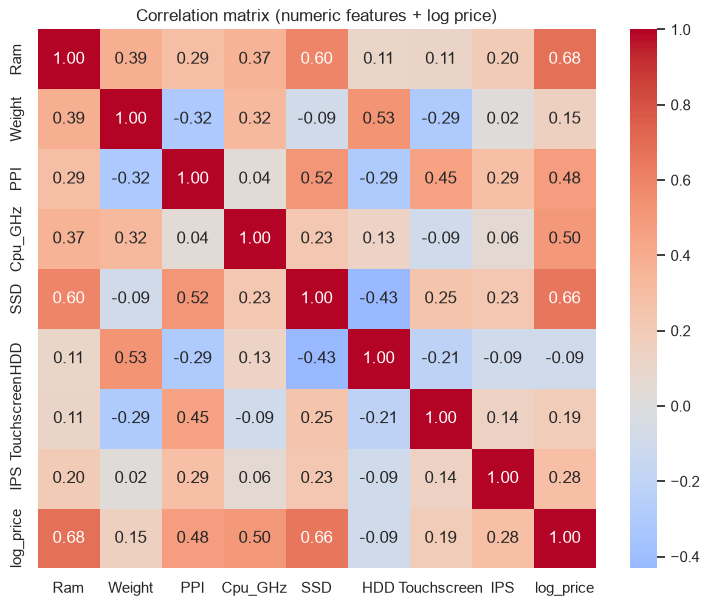

Inches alone vs log(Price): 0.04  -> weak, so it lives on inside PPI instead

Ram            0.68
SSD            0.66
Cpu_GHz        0.50
PPI            0.48
IPS            0.28
Touchscreen    0.19
Weight         0.15
HDD           -0.09
Name: log_price, dtype: float64


In [9]:
corr = df[NUMERIC_FEATURES].assign(log_price=np.log(df[TARGET])).corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features + log price)")
plt.show()

inches_corr = np.corrcoef(raw["Inches"], np.log(raw["Price"]))[0, 1]
print(f"Inches alone vs log(Price): {inches_corr:.2f}  -> weak, so it lives on inside PPI instead\n")
print(corr["log_price"].drop("log_price").sort_values(ascending=False).round(2))

**Reading the heatmap:** RAM (0.68) and SSD (0.66) are the strongest signals. HDD is slightly *negative* because cheap laptops ship with a large hard disk instead of an SSD. That's still useful, so we keep it.

## 6. Preprocessing: split first, then encode and scale
1. **Train/test split (80/20) before anything is fitted.** The test set stays locked until the very end. That way our final score shows how the model does on laptops it has never seen.
2. **One-hot encoding** turns categories into 0/1 columns (`Company_Apple`, `Company_Dell`, …), because models only understand numbers.
3. **Standard scaling** puts numbers on the same scale (mean 0, std 1). Without it, `SSD` (0–1000) would drown out `Cpu_GHz` (1–3). Gradient descent and KNN especially need this.
4. The scaler and encoder learn their settings from the **train set only**. Fitting on all the data would leak test information.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df[FEATURES]
y = np.log(df[TARGET])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

preprocessor = ColumnTransformer(
    [("num", StandardScaler(), NUMERIC_FEATURES),
     ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES)],
    sparse_threshold=0,
)
X_train_enc = preprocessor.fit_transform(X_train)   # learns mean/std/categories from TRAIN only
X_test_enc = preprocessor.transform(X_test)          # just applies them
print(f"{X_train.shape[1]} features -> {X_train_enc.shape[1]} columns after one-hot encoding")

Train: (1018, 13) | Test: (255, 13)
13 features -> 44 columns after one-hot encoding


## 7. Linear Regression from scratch, with Gradient Descent
**Idea:** price ≈ `w₁·RAM + w₂·SSD + … + b`. The model draws the best-fitting *hyperplane* through the data (a line in 2D, a flat surface in many dimensions).

**Cost function (MSE):** J(w, b) = average of (prediction − actual)². Lower is better.

**Gradient descent:** start with all weights = 0, then repeat:
- `w = w − α · ∂J/∂w`  and  `b = b − α · ∂J/∂b`
- The gradient points uphill, so we step the *opposite* way. **α (learning rate)** is the step size.
- Repeat until the cost stops falling (**convergence**).

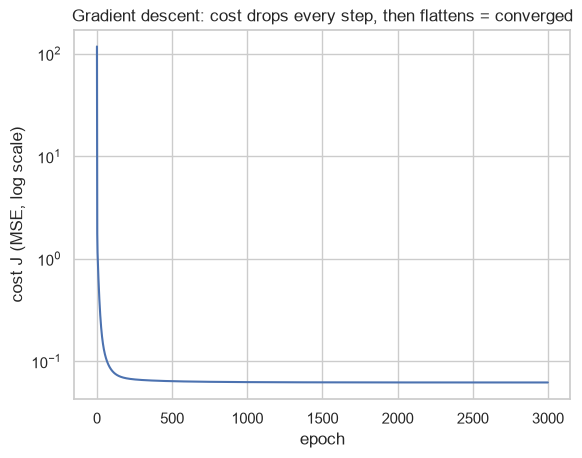

Cost at start: 117.82 -> after 3000 steps: 0.0620


In [11]:
X_gd = np.asarray(X_train_enc, dtype=float)
y_gd = y_train.to_numpy()
m, n = X_gd.shape


def gradient_descent(lr, epochs):
    w, b, costs = np.zeros(n), 0.0, []
    for _ in range(epochs):
        error = X_gd @ w + b - y_gd                 # prediction - actual
        costs.append((error ** 2).mean())           # J = MSE
        w -= lr * (2 / m) * (X_gd.T @ error)        # dJ/dw
        b -= lr * (2 / m) * error.sum()             # dJ/db
    return w, b, costs


w_gd, b_gd, costs = gradient_descent(lr=0.2, epochs=3000)
plt.plot(costs)
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("cost J (MSE, log scale)")
plt.title("Gradient descent: cost drops every step, then flattens = converged")
plt.show()
print(f"Cost at start: {costs[0]:.2f} -> after 3000 steps: {costs[-1]:.4f}")

**Learning rate matters:** too small (0.001) and it crawls. Too big (0.35) and every step overshoots the minimum, so the cost *explodes* instead of falling.

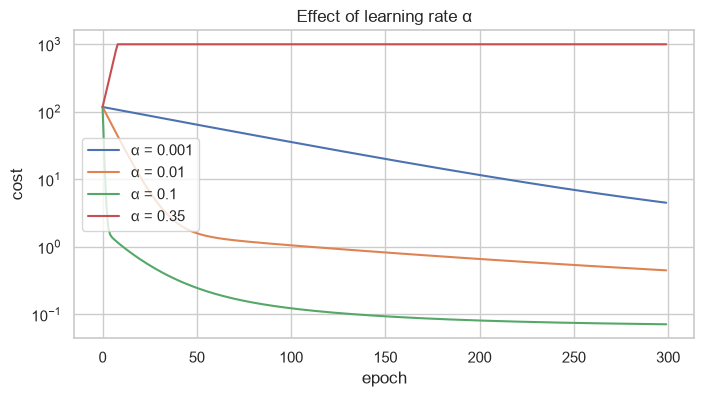

In [12]:
plt.figure(figsize=(8, 4))
for lr in [0.001, 0.01, 0.1, 0.35]:
    _, _, c = gradient_descent(lr, epochs=300)
    plt.plot(np.clip(c, None, 1e3), label=f"α = {lr}")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("cost")
plt.legend()
plt.title("Effect of learning rate α")
plt.show()

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

lin = LinearRegression().fit(X_train_enc, y_train)
print(f"Train R² - our gradient descent    : {r2_score(y_train, X_gd @ w_gd + b_gd):.4f}")
print(f"Train R² - sklearn LinearRegression: {r2_score(y_train, lin.predict(X_train_enc)):.4f}")
print("-> Same answer. sklearn just solves it in one shot (least squares) instead of stepping downhill.")

Train R² - our gradient descent    : 0.8369
Train R² - sklearn LinearRegression: 0.8369
-> Same answer. sklearn just solves it in one shot (least squares) instead of stepping downhill.


**Interpreting the weights.** Because we predict *log* price, `exp(weight) − 1` is a **% change in price** for +1 standard deviation of that feature (all else equal):

In [14]:
names = preprocessor.get_feature_names_out()
numeric_effect = pd.Series(lin.coef_[: len(NUMERIC_FEATURES)], index=NUMERIC_FEATURES)
stds = X_train[NUMERIC_FEATURES].std()
pd.DataFrame({
    "+1 std means": [f"+{stds[f]:.1f} {u}" for f, u in zip(NUMERIC_FEATURES, ["GB", "kg", "PPI", "GHz", "GB", "GB", "", ""])],
    "price change %": ((np.exp(numeric_effect) - 1) * 100).round(1),
}).sort_values("price change %", ascending=False)

,+1 std means,price change %
Ram,+5.2 GB,13.0
SSD,+188.1 GB,11.7
PPI,+43.8 PPI,11.3
Cpu_GHz,+0.5 GHz,7.3
Weight,+0.7 kg,5.4
IPS,+0.5,2.6
HDD,+516.1 GB,0.1
Touchscreen,+0.4,-2.8


## 8. Evaluation metrics
To get an honest score without touching the test set, we use **5-fold cross-validation** on the training data. The model is trained on 4 parts and scored on the 5th, five times over, and every laptop gets a prediction from a model that never saw it.

| Metric | Meaning in plain words |
|---|---|
| **MSE** | average squared error. Punishes big misses hard, but its unit is ₹² |
| **RMSE** | √MSE, back in ₹. A "typical" error |
| **MAE** | average absolute error in ₹. Easiest to explain to a manager |
| **R²** | share of price variation explained. 1 = perfect, 0 = no better than guessing the average |

In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, cross_val_predict

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def report(y_true_log, y_pred_log):
    y_true, y_pred = np.exp(y_true_log), np.exp(y_pred_log)
    return {
        "R² (log)": r2_score(y_true_log, y_pred_log),
        "RMSE (log)": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "MAE (₹)": mean_absolute_error(y_true, y_pred),
        "RMSE (₹)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": np.mean(np.abs(y_true - y_pred) / y_true) * 100,
    }


lin_pipe = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
lin_cv_pred = cross_val_predict(lin_pipe, X_train, y_train, cv=kf)
pd.Series(report(y_train, lin_cv_pred)).round(3).to_frame("Linear Regression (5-fold CV)")

,Linear Regression (5-fold CV)
R² (log),0.817
RMSE (log),0.264
MAE (₹),13223.305
RMSE (₹),22065.683
MAPE (%),20.845


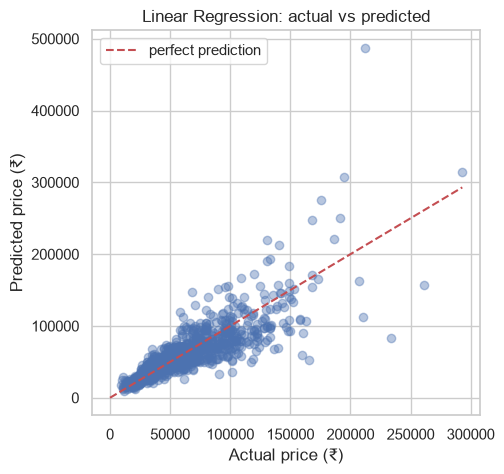

In [16]:
plt.figure(figsize=(5, 5))
plt.scatter(np.exp(y_train), np.exp(lin_cv_pred), alpha=0.4)
lims = [0, np.exp(y_train).max()]
plt.plot(lims, lims, "r--", label="perfect prediction")
plt.xlabel("Actual price (₹)")
plt.ylabel("Predicted price (₹)")
plt.title("Linear Regression: actual vs predicted")
plt.legend()
plt.show()

**Verdict:** a solid baseline (about 82% of the variation explained). It misses most on expensive laptops, where price isn't a straight-line function of specs. *Example:* going from 16 to 32 GB RAM in a gaming laptop adds far more than 4 → 8 GB in a budget one. Tree-based models can capture these **non-linear interactions**.

## 9. Overfitting vs underfitting
A Decision Tree lets us dial model complexity with `max_depth`:
- **Too shallow → underfitting.** Too simple: bad on train *and* validation (high bias).
- **Too deep → overfitting.** Memorises the training laptops: near-perfect on train, worse on new ones (high variance).
- The sweet spot is where the **validation** score peaks.

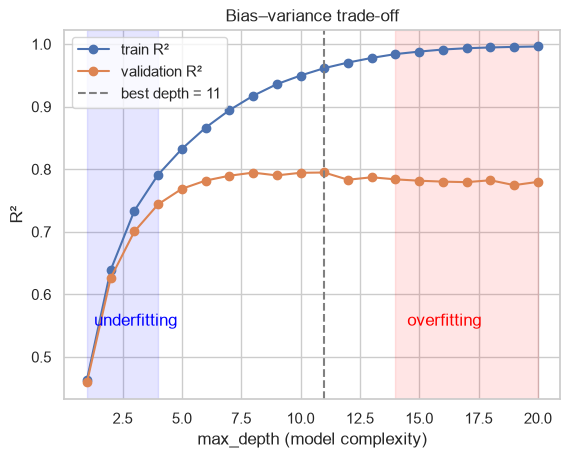

In [17]:
from sklearn.model_selection import validation_curve
from sklearn.tree import DecisionTreeRegressor

depths = list(range(1, 21))
train_scores, val_scores = validation_curve(
    Pipeline([("prep", preprocessor), ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
    X_train, y_train, param_name="model__max_depth", param_range=depths, cv=kf, scoring="r2",
)
plt.plot(depths, train_scores.mean(axis=1), "o-", label="train R²")
plt.plot(depths, val_scores.mean(axis=1), "o-", label="validation R²")
best_depth = depths[int(np.argmax(val_scores.mean(axis=1)))]
plt.axvline(best_depth, color="grey", ls="--", label=f"best depth = {best_depth}")
plt.axvspan(1, 4, alpha=0.1, color="blue")
plt.text(1.3, 0.55, "underfitting", color="blue")
plt.axvspan(best_depth + 3, 20, alpha=0.1, color="red")
plt.text(best_depth + 3.5, 0.55, "overfitting", color="red")
plt.xlabel("max_depth (model complexity)")
plt.ylabel("R²")
plt.legend()
plt.title("Bias–variance trade-off")
plt.show()

## 10. Compare models with cross-validation
Same 5 folds for every model, so it's a fair race. A low **std** across folds means the model is stable.
- **Bagging: Random Forest.** Many deep trees, each trained on a random sample of rows and features. Averaging them cancels out individual trees' overfitting.
- **Boosting: AdaBoost, Gradient Boosting, XGBoost.** Trees are built *one after another*, and each new tree focuses on the mistakes of the previous ones.

In [18]:
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import cross_validate
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

models = {
    "Linear Regression": LinearRegression(),
    "KNN (k=5)": KNeighborsRegressor(n_neighbors=5),
    f"Decision Tree (depth={best_depth})": DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE),
    "Random Forest (bagging)": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "AdaBoost (boosting)": AdaBoostRegressor(random_state=RANDOM_STATE),
    "Gradient Boosting (boosting)": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "XGBoost (boosting)": XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1),
}


def cv_score(model):
    s = cross_validate(Pipeline([("prep", preprocessor), ("model", model)]), X_train, y_train, cv=kf,
                       scoring=("r2", "neg_root_mean_squared_error"))
    return {"CV R² mean": s["test_r2"].mean(), "CV R² std": s["test_r2"].std(),
            "CV RMSE (log)": -s["test_neg_root_mean_squared_error"].mean()}


results = pd.DataFrame({name: cv_score(model) for name, model in models.items()}).T
results.sort_values("CV R² mean", ascending=False).round(3)

,CV R² mean,CV R² std,CV RMSE (log)
XGBoost (boosting),0.878,0.011,0.215
Random Forest (bagging),0.873,0.024,0.218
Gradient Boosting (boosting),0.871,0.007,0.221
KNN (k=5),0.835,0.008,0.250
Linear Regression,0.816,0.022,0.264
AdaBoost (boosting),0.800,0.012,0.275
Decision Tree (depth=11),0.795,0.036,0.277


## 11. Hyperparameter tuning
*Parameters* are learned from data (the weights). *Hyperparameters* are settings **we** choose before training (number of trees, depth, learning rate).
- **GridSearchCV** tries *every* combination. Thorough, but slow when the grid grows.
- **RandomizedSearchCV** tries a fixed number of *random* combinations. Much faster on big search spaces, and usually finds something just as good.

In [19]:
from sklearn.model_selection import GridSearchCV

rf_grid = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
    param_grid={
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 15],
        "model__max_features": [0.5, 1.0],
        "model__min_samples_leaf": [1, 2],
    },
    cv=kf, scoring="r2", n_jobs=1,
)
rf_grid.fit(X_train, y_train)
print(f"GridSearchCV tried {len(rf_grid.cv_results_['params'])} combos x 5 folds")
print("Best params:", rf_grid.best_params_)
print(f"Best CV R²: {rf_grid.best_score_:.3f}  (default RF: {results.loc['Random Forest (bagging)', 'CV R² mean']:.3f})")

GridSearchCV tried 16 combos x 5 folds
Best params: {'model__max_depth': 15, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best CV R²: 0.882  (default RF: 0.873)


In [20]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

xgb_search = RandomizedSearchCV(
    Pipeline([("prep", preprocessor), ("model", XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
    param_distributions={
        "model__n_estimators": randint(200, 1200),
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_depth": randint(2, 8),
        "model__subsample": uniform(0.6, 0.4),
        "model__colsample_bytree": uniform(0.4, 0.6),
        "model__min_child_weight": randint(1, 6),
    },
    n_iter=40, cv=kf, scoring="r2", random_state=RANDOM_STATE, n_jobs=1,
)
xgb_search.fit(X_train, y_train)
print("RandomizedSearchCV tried 40 random combos x 5 folds")
print("Best params:", {k.replace("model__", ""): round(v, 3) if isinstance(v, float) else v
                       for k, v in xgb_search.best_params_.items()})
print(f"Best CV R²: {xgb_search.best_score_:.3f}  (default XGBoost: {results.loc['XGBoost (boosting)', 'CV R² mean']:.3f})")

RandomizedSearchCV tried 40 random combos x 5 folds
Best params: {'colsample_bytree': np.float64(0.446), 'learning_rate': np.float64(0.024), 'max_depth': 7, 'min_child_weight': 4, 'n_estimators': 777, 'subsample': np.float64(0.85)}
Best CV R²: 0.902  (default XGBoost: 0.878)


## 12. Stacking ensemble
**Stacking** trains different kinds of models (here Linear + Random Forest + XGBoost). A small *meta-model* then learns how much to trust each one. It works when the base models make **different kinds of mistakes**.

In [21]:
from sklearn.ensemble import StackingRegressor

stack = StackingRegressor(
    estimators=[
        ("linear", LinearRegression()),
        ("rf", rf_grid.best_estimator_.named_steps["model"]),
        ("xgb", xgb_search.best_estimator_.named_steps["model"]),
    ],
    final_estimator=LinearRegression(),
    cv=5,
)
stack_pipe = Pipeline([("prep", preprocessor), ("model", stack)])
results.loc["Random Forest (GridSearch-tuned)"] = cv_score(rf_grid.best_estimator_.named_steps["model"])
results.loc["XGBoost (RandomSearch-tuned)"] = cv_score(xgb_search.best_estimator_.named_steps["model"])
results.loc["Stacking (Linear + RF + XGB)"] = cv_score(stack)
results = results.sort_values("CV R² mean", ascending=False)
results.round(3)

,CV R² mean,CV R² std,CV RMSE (log)
XGBoost (RandomSearch-tuned),0.902,0.015,0.192
Stacking (Linear + RF + XGB),0.901,0.014,0.193
Random Forest (GridSearch-tuned),0.882,0.021,0.210
XGBoost (boosting),0.878,0.011,0.215
Random Forest (bagging),0.873,0.024,0.218
Gradient Boosting (boosting),0.871,0.007,0.221
KNN (k=5),0.835,0.008,0.250
Linear Regression,0.816,0.022,0.264
AdaBoost (boosting),0.800,0.012,0.275
Decision Tree (depth=11),0.795,0.036,0.277


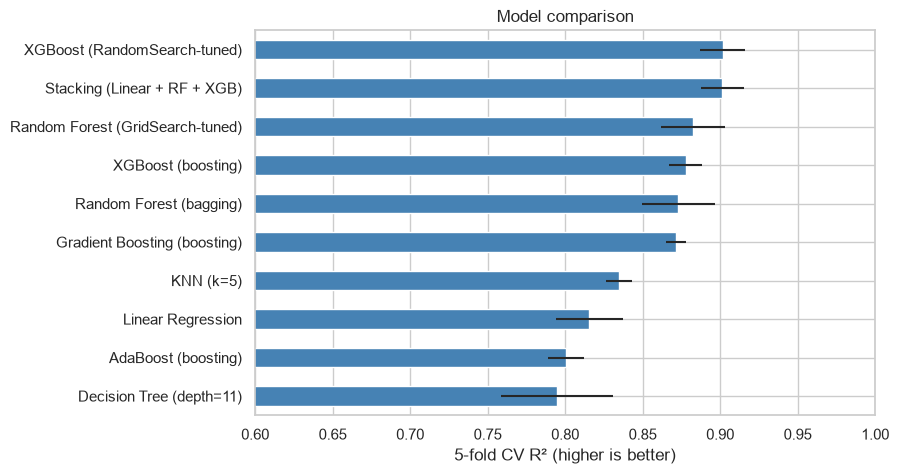

In [22]:
plt.figure(figsize=(8, 5))
results["CV R² mean"].sort_values().plot.barh(xerr=results["CV R² std"], color="steelblue")
plt.xlim(0.6, 1)
plt.xlabel("5-fold CV R² (higher is better)")
plt.title("Model comparison")
plt.show()

## 13. Final evaluation on the untouched test set
We pick the best model **by cross-validation score** and only now open the test set, *once*.

In [23]:
candidates = {
    "Linear Regression": lin_pipe,
    "Random Forest (GridSearch-tuned)": rf_grid.best_estimator_,
    "XGBoost (RandomSearch-tuned)": xgb_search.best_estimator_,
    "Stacking (Linear + RF + XGB)": stack_pipe,
}
best_name = max(candidates, key=lambda k: results.loc[k, "CV R² mean"])
final_model = candidates[best_name]
print("Chosen by CV:", best_name)

test_rows = {}
for name in ["Linear Regression", best_name]:
    model = candidates[name].fit(X_train, y_train)
    test_rows[name] = report(y_test, model.predict(X_test))
test_report = pd.DataFrame(test_rows).T.round(3)
test_report

Chosen by CV: XGBoost (RandomSearch-tuned)


,R² (log),RMSE (log),MAE (₹),RMSE (₹),MAPE (%)
Linear Regression,0.815,0.271,12748.544,20933.822,21.506
XGBoost (RandomSearch-tuned),0.913,0.185,9151.840,14274.502,14.816


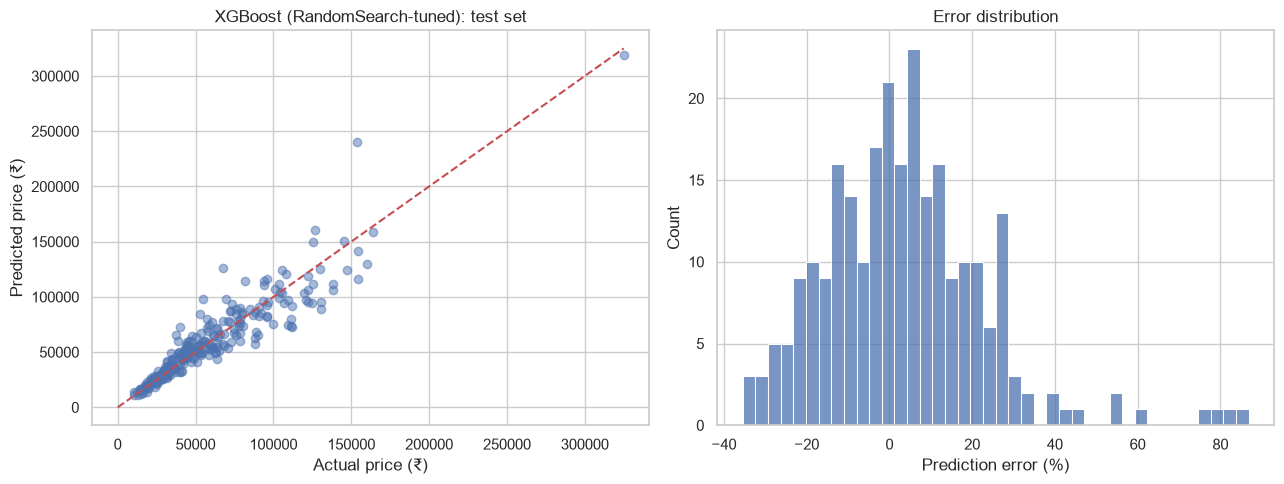

61% of test laptops predicted within ±15% of the real price


In [24]:
test_pred = final_model.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(np.exp(y_test), np.exp(test_pred), alpha=0.5)
lims = [0, np.exp(y_test).max()]
ax[0].plot(lims, lims, "r--")
ax[0].set(xlabel="Actual price (₹)", ylabel="Predicted price (₹)", title=f"{best_name}: test set")
pct_err = (np.exp(test_pred) - np.exp(y_test)) / np.exp(y_test) * 100
sns.histplot(pct_err, bins=40, ax=ax[1])
ax[1].set(xlabel="Prediction error (%)", title="Error distribution")
plt.tight_layout()
plt.show()
print(f"{(pct_err.abs() <= 15).mean():.0%} of test laptops predicted within ±15% of the real price")

**Which features drive price?** *Permutation importance* shuffles one column at a time and measures how much worse the model gets. It works for any model, and it scores the **original** features (not the one-hot pieces).

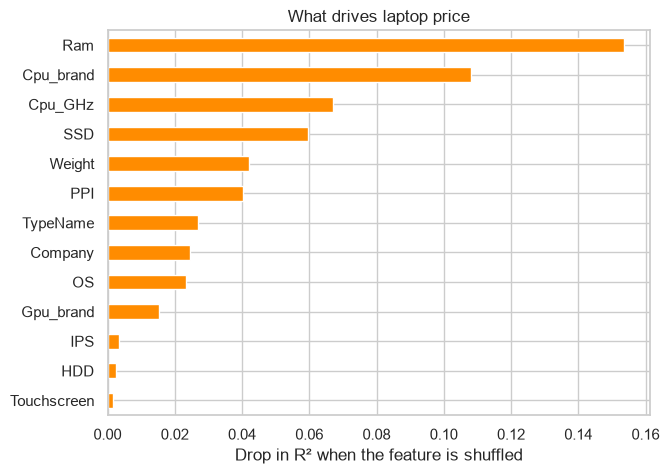

In [25]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="r2")
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
importance.plot.barh(figsize=(7, 5), color="darkorange")
plt.xlabel("Drop in R² when the feature is shuffled")
plt.title("What drives laptop price")
plt.show()

## 14. Unsupervised learning: market segments (no price used!)
**K-Means** groups laptops with similar specs. We give it **only hardware specs, no price, no labels**, and check afterwards whether the groups make business sense.

How K-Means works: pick K centres → assign each laptop to the nearest centre → move each centre to the mean of its laptops → repeat until nothing changes.
**Choosing K:** the *elbow method* (inertia stops dropping sharply) plus the *silhouette score* (how well separated the clusters are, −1 to 1).

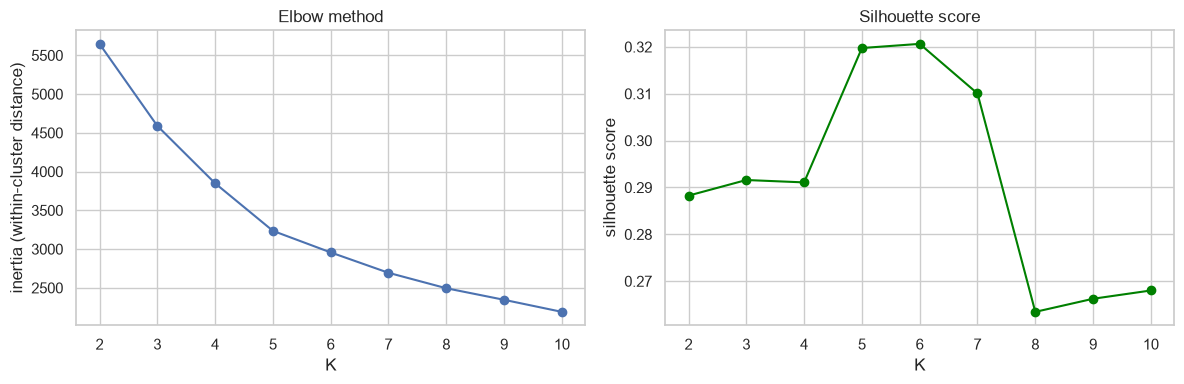

In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

seg_features = ["Ram", "SSD", "HDD", "PPI", "Cpu_GHz", "Weight"]
seg_scaler = StandardScaler()
X_seg = seg_scaler.fit_transform(df[seg_features])

ks = range(2, 11)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_seg)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_seg, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, "o-")
ax[0].set(xlabel="K", ylabel="inertia (within-cluster distance)", title="Elbow method")
ax[1].plot(ks, silhouettes, "o-", color="green")
ax[1].set(xlabel="K", ylabel="silhouette score", title="Silhouette score")
plt.tight_layout()
plt.show()

In [27]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_seg)
df["Segment_id"] = kmeans.labels_
profile = df.groupby("Segment_id").agg(
    laptops=("Price", "size"), avg_price=("Price", "mean"), Ram=("Ram", "mean"), SSD=("SSD", "mean"),
    HDD=("HDD", "mean"), PPI=("PPI", "mean"), Cpu_GHz=("Cpu_GHz", "mean"), Weight=("Weight", "mean"),
    pct_gaming=("TypeName", lambda s: (s == "Gaming").mean() * 100),
).sort_values("avg_price")
profile.round(1)

,laptops,avg_price,Ram,SSD,HDD,PPI,Cpu_GHz,Weight,pct_gaming
Segment_id,,,,,,,,,
2,439,39370.9,6.2,28.7,905.5,122.6,2.3,2.2,15.5
1,535,53321.5,6.7,217.0,5.0,144.9,2.2,1.7,2.6
3,155,100498.1,12.3,459.5,25.8,224.2,2.4,1.5,3.2
0,144,108735.6,17.6,298.0,916.7,145.5,2.7,3.1,81.9


We name each cluster from its profile above (cheapest → priciest). **Price was never shown to K-Means**, yet the clusters come out ordered by price. That shows the segments are real.

In [28]:
def name_segment(row):
    if row["Weight"] > 2.8 and row["Ram"] >= 12:
        return "Gaming / Workstation"
    if row["avg_price"] == profile["avg_price"].min():
        return "Budget"
    if row["PPI"] > 170 or (row["Weight"] < 1.6 and row["SSD"] > 200):
        return "Premium Thin & Light"
    return "Mainstream"


segment_names = {seg_id: name_segment(row) for seg_id, row in profile.iterrows()}
df["Segment"] = df["Segment_id"].map(segment_names)
print(segment_names)
df.groupby("Segment")["Price"].describe()[["count", "mean", "50%"]].round(0).sort_values("mean")

{2: 'Budget', 1: 'Mainstream', 3: 'Premium Thin & Light', 0: 'Gaming / Workstation'}


,count,mean,50%
Segment,,,
Budget,439.0,39371.0,35617.0
Mainstream,535.0,53322.0,50669.0
Premium Thin & Light,155.0,100498.0,99048.0
Gaming / Workstation,144.0,108736.0,101205.0


### PCA: viewing 6 dimensions in 2
We can't plot 6 dimensions. **PCA** finds new axes (principal components) that keep as much of the spread (variance) as possible. PC1 and PC2 together give the best 2D "shadow" of the data.

PC1 + PC2 keep 69% of the information (36% + 33%)

What PC1 is made of (loadings):
SSD        0.61
PPI        0.51
Ram        0.40
Cpu_GHz    0.17
Weight    -0.17
HDD       -0.37


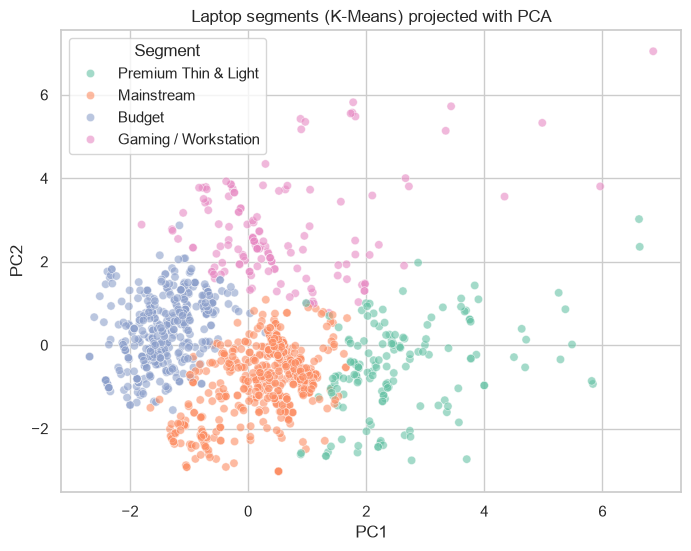

In [29]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X_seg)
print(f"PC1 + PC2 keep {pca.explained_variance_ratio_.sum():.0%} of the information "
      f"({pca.explained_variance_ratio_[0]:.0%} + {pca.explained_variance_ratio_[1]:.0%})")
print("\nWhat PC1 is made of (loadings):")
print(pd.Series(pca.components_[0], index=seg_features).round(2).sort_values(ascending=False).to_string())

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=df["Segment"], alpha=0.6, palette="Set2")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Laptop segments (K-Means) projected with PCA")
plt.show()

**Curse of dimensionality:** after one-hot encoding the model sees ~40 columns. With more dimensions, data gets sparse and distances lose meaning. That's why KNN struggles here. PCA tells us how many dimensions we *really* need:

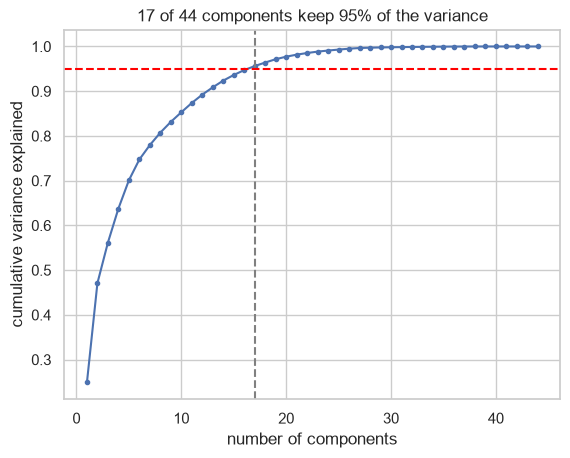

In [30]:
pca_full = PCA().fit(X_train_enc)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95) + 1)
plt.plot(range(1, len(cum) + 1), cum, "o-", markersize=3)
plt.axhline(0.95, color="red", ls="--")
plt.axvline(n95, color="grey", ls="--")
plt.xlabel("number of components")
plt.ylabel("cumulative variance explained")
plt.title(f"{n95} of {X_train_enc.shape[1]} components keep 95% of the variance")
plt.show()

### DBSCAN: finding unusual laptops
K-Means puts *every* point in a cluster. **DBSCAN** groups points in *dense* regions, and points in sparse regions get label **−1 = noise/outlier**. It needs two settings:
- `eps`: how close counts as a "neighbour"
- `min_samples`: how many neighbours make a dense core

We pick `eps` from the k-distance plot (the "knee").

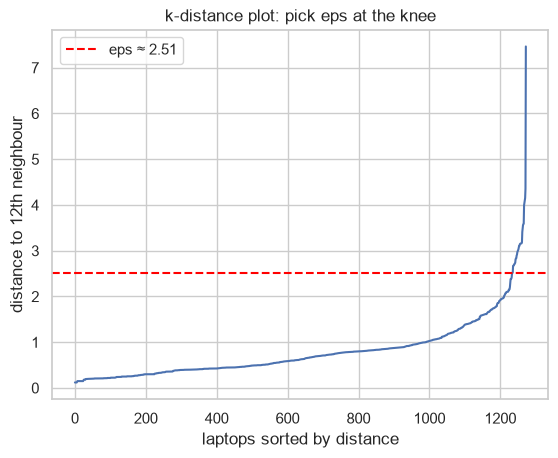

DBSCAN flagged 20 unusual laptops out of 1273


,Company,TypeName,Ram,SSD,HDD,PPI,Weight,Price
196,Razer,Gaming,32,1000.0,0.0,254.67,3.49,324954.7200
830,Razer,Gaming,32,512.0,0.0,254.67,3.49,292986.7200
610,Lenovo,Notebook,32,1000.0,0.0,282.42,2.50,261018.7200
1066,Asus,Gaming,64,1000.0,0.0,127.34,3.58,211788.0000
723,Dell,Gaming,32,1000.0,1000.0,254.67,4.36,194972.8320
780,Dell,Gaming,32,1000.0,1000.0,127.34,4.42,191211.2640
744,Lenovo,Workstation,16,1000.0,0.0,282.42,2.50,175770.7200
659,Dell,Gaming,32,512.0,1000.0,254.67,4.42,167691.8736
758,Dell,Gaming,16,256.0,1000.0,282.42,4.42,152859.7872
190,Lenovo,2 in 1 Convertible,16,1000.0,0.0,209.80,1.42,150462.7200


In [31]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

min_samples = 2 * len(seg_features)
dist, _ = NearestNeighbors(n_neighbors=min_samples).fit(X_seg).kneighbors(X_seg)
k_dist = np.sort(dist[:, -1])
plt.plot(k_dist)
plt.ylabel(f"distance to {min_samples}th neighbour")
plt.xlabel("laptops sorted by distance")
plt.title("k-distance plot: pick eps at the knee")
eps = float(np.quantile(k_dist, 0.97))
plt.axhline(eps, color="red", ls="--", label=f"eps ≈ {eps:.2f}")
plt.legend()
plt.show()

db = DBSCAN(eps=eps, min_samples=min_samples).fit(X_seg)
df["Outlier"] = db.labels_ == -1
print(f"DBSCAN flagged {df['Outlier'].sum()} unusual laptops out of {len(df)}")
df.loc[df["Outlier"], ["Company", "TypeName", "Ram", "SSD", "HDD", "PPI", "Weight", "Price"]] \
  .sort_values("Price", ascending=False).head(10)

These are the odd ones out: mostly extreme configurations (32–64 GB RAM, 1 TB SSD + 1 TB HDD, 4K screens, 4+ kg gaming rigs). They're worth a human check before listing them, because there are few similar laptops for the price model to learn from.

## 15. Save the model for the app
We refit the chosen pipeline on **all** the data (train + test) now that evaluation is done, and save everything the app needs.

In [32]:
import joblib

final_model.fit(X, y)
artifact = {
    "model": final_model,
    "model_name": best_name,
    "test_metrics": test_report.loc[best_name].to_dict(),
    "seg_scaler": seg_scaler,
    "kmeans": kmeans,
    "seg_features": seg_features,
    "segment_names": segment_names,
    "options": {c: sorted(df[c].unique().tolist()) for c in CATEGORICAL_FEATURES},
}
joblib.dump(artifact, "model.joblib")
print("Saved model.joblib ->", best_name)

Saved model.joblib -> XGBoost (RandomSearch-tuned)


## 16. Summary
- **Cleaning + feature engineering** (PPI, CPU groups, SSD/HDD split, log target) turned 12 messy columns into 13 clean, meaningful features.
- **Linear Regression** (built from scratch with gradient descent and matched to sklearn) explains ~82% of price variation.
- **XGBoost tuned with RandomizedSearchCV** captures non-linear effects: test R² ≈ 0.91, and the average error drops from ~₹12.7k (linear) to ~₹9.2k (≈15% MAPE).
- **K-Means** found market segments from specs alone, and they line up with price. **DBSCAN** flagged unusual configurations for manual review.

**What I'd do next:** add newer laptops (the data is from ~2017–18), add CPU generation and GPU model tiers as features, and keep an eye on accuracy as prices drift over time.